In [1]:
import pandas as pd 

In [2]:
df = pd.read_csv(r"C:\Users\ARIO\Documents\for IK saber\AI4I\ai4i2020.csv")
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [3]:
df.shape

(10000, 14)

In [4]:
df.isnull().sum()

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

In [5]:
df['Machine failure'].value_counts()

Machine failure
0    9661
1     339
Name: count, dtype: int64

In [6]:
df[['TWF','HDF','PWF','OSF','RNF']].sum()

TWF     46
HDF    115
PWF     95
OSF     98
RNF     19
dtype: int64

In [7]:
df[['TWF','HDF','PWF','OSF','RNF']].sum(axis=1).value_counts()

0    9652
1     324
2      23
3       1
Name: count, dtype: int64

In [8]:
df['failure_count'] = df[['TWF','HDF','PWF','OSF','RNF']].sum(axis=1)

cdf = df[df['failure_count']<= 1].copy()
print(cdf.shape)
cdf.head()

(9976, 15)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF,failure_count
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0,0


In [9]:
def get_failure_type (row) : 
    if row ['TWF'] == 1 :
        return 'TWF'
    elif  row ['HDF'] == 1 : 
        return 'HDF'
    elif  row ['PWF'] == 1 : 
        return 'PWF'
    elif row ['OSF']  == 1: 
        return 'OSF'
    elif row ['RNF'] ==1 : 
        return 'RNF'
    else : 
        return 'Healthy'

cdf['failure_type']  =  cdf.apply(get_failure_type,axis=1)
cdf['failure_type'].value_counts()

failure_type
Healthy    9652
HDF         106
PWF          80
OSF          78
TWF          42
RNF          18
Name: count, dtype: int64

In [10]:
cdf.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF,failure_count,failure_type
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0,0,Healthy
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0,0,Healthy
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0,0,Healthy
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0,0,Healthy
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0,0,Healthy


In [11]:
from sklearn.preprocessing import LabelEncoder 

le_type = LabelEncoder()
cdf['type_encoded'] = le_type.fit_transform(cdf['Type'])

In [12]:
le_failure = LabelEncoder() 
cdf['failure_encoded'] = le_failure.fit_transform(cdf['failure_type'])

In [13]:
cdf.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF,failure_count,failure_type,type_encoded,failure_encoded
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0,0,Healthy,2,1
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0,0,Healthy,1,1
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0,0,Healthy,1,1
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0,0,Healthy,1,1
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0,0,Healthy,1,1


In [14]:
ncdf = cdf.drop(columns=['UDI', 'Product ID', 'Type', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF', 'failure_count'])
ncdf.head()

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],failure_type,type_encoded,failure_encoded
0,298.1,308.6,1551,42.8,0,Healthy,2,1
1,298.2,308.7,1408,46.3,3,Healthy,1,1
2,298.1,308.5,1498,49.4,5,Healthy,1,1
3,298.2,308.6,1433,39.5,7,Healthy,1,1
4,298.2,308.7,1408,40.0,9,Healthy,1,1


In [19]:
features = ['type_encoded', 'Air temperature [K]', 'Process temperature [K]', 
            'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']

x = cdf[features]
y = cdf['failure_encoded']

print(x.shape)
print(y.shape)

(9976, 6)
(9976,)


In [22]:
from sklearn.model_selection import train_test_split

x_train , x_test , y_train , y_test = train_test_split(x,y,test_size=0.2,random_state=42, stratify=y)
print(x_test.shape , x_train.shape)

(1996, 6) (7980, 6)


In [23]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(n_estimators=100,random_state=42,class_weight='balanced')
model.fit(x_train,y_train)

RandomForestClassifier(class_weight='balanced', random_state=42)

In [24]:
from sklearn.metrics import classification_report , confusion_matrix

y_hat = model.predict(x_test)

report = classification_report(y_test,y_hat , target_names=le_failure.classes_)
print(report)

              precision    recall  f1-score   support

         HDF       1.00      0.86      0.92        21
     Healthy       0.98      1.00      0.99      1931
         OSF       1.00      0.56      0.72        16
         PWF       0.83      0.31      0.45        16
         RNF       0.00      0.00      0.00         4
         TWF       0.00      0.00      0.00         8

    accuracy                           0.98      1996
   macro avg       0.64      0.46      0.51      1996
weighted avg       0.98      0.98      0.98      1996



C:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


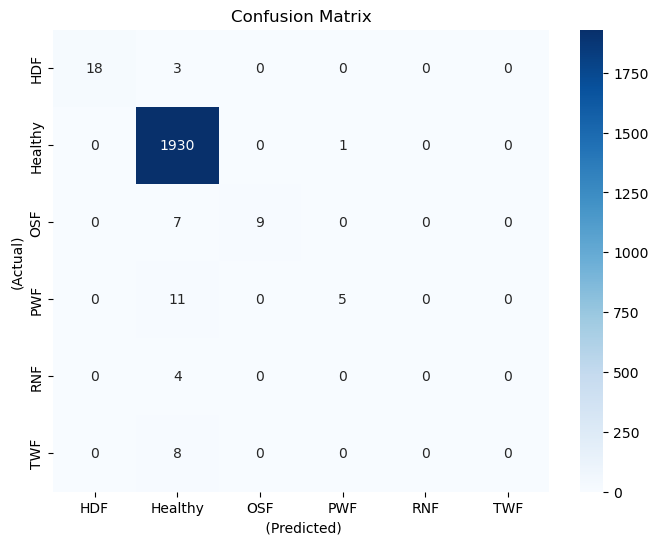

In [26]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_hat)

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=le_failure.classes_,
            yticklabels=le_failure.classes_)
plt.xlabel(' (Predicted)')
plt.ylabel( '(Actual)')
plt.title('Confusion Matrix')
plt.show()

In [30]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42, k_neighbors=3)
X_train_balanced, y_train_balanced = smote.fit_resample(x_train, y_train)

print("befor SMOTE:", y_train.value_counts().to_dict())
print (" after SMOTE:", y_train_balanced.value_counts().to_dict())

befor SMOTE: {1: 7721, 0: 85, 3: 64, 2: 62, 5: 34, 4: 14}
 after SMOTE: {1: 7721, 2: 7721, 0: 7721, 3: 7721, 5: 7721, 4: 7721}


In [32]:
model_balanced = RandomForestClassifier(n_estimators=100, random_state=42)
model_balanced.fit(X_train_balanced, y_train_balanced)

y_hat_balanced = model_balanced.predict(x_test)

print(classification_report(y_test, y_hat_balanced, target_names=le_failure.classes_))

              precision    recall  f1-score   support

         HDF       0.74      0.95      0.83        21
     Healthy       0.99      0.98      0.99      1931
         OSF       0.74      0.88      0.80        16
         PWF       0.93      0.88      0.90        16
         RNF       0.00      0.00      0.00         4
         TWF       0.06      0.12      0.08         8

    accuracy                           0.97      1996
   macro avg       0.58      0.63      0.60      1996
weighted avg       0.98      0.97      0.98      1996

